# Modélisation 2D - Circulaire

In [1]:
distancesmoy_au_soleil = {
    "Mercure": 0.38,
    "Vénus": 0.72,
    "Terre": 1.00,
    "Mars": 1.52,
    "Jupiter": 5.21,
    "Saturne": 9.54,
    "Uranus": 19.18,
    "Neptune": 30.11
}
revol_planetes_j = {
    "Mercure": 87.969,
    "Vénus": 224.701,
    "Terre": 365.257,
    "Mars": 686.96,
    "Jupiter" : 4335.355,
    "Saturne" : 10757.737,
    "Uranus" : 30708.16,
    "Neptune" : 60224.904,
}


In [2]:
theta_jour = {
    
}

Lune = ("Terre",0.1,27.32,2*pi/27.32)
Deimos = ("Mars", 0.1,1.262, 2*pi/1.262) 
distances_soleil = {}
for i in distancesmoy_au_soleil.keys():
    if distancesmoy_au_soleil[i] < 2:
        distances_soleil[i] = distancesmoy_au_soleil[i]

for i in distances_soleil.keys():
    theta_jour[i] = 2*pi/revol_planetes_j[i]

### Référentiel Héliocentrique

Animation with 70 frames
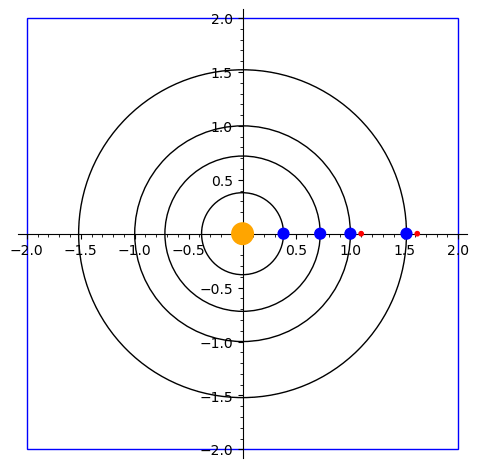

In [3]:
def dessine_planetes(k):
    plt = point2d((0,0))
    for i in distances_soleil.keys():
        theta = 5*k*theta_jour[i]
        x = distances_soleil[i]*cos(theta)
        y = distances_soleil[i]*sin(theta)
        plt += circle(((x,y)), 0.05 , fill = True, color = "blue")
        if i == "Terre":
            plt += circle((x + Lune[1]*cos(5*k*Lune[3]),y + Lune[1]*sin(5*k*Lune[3])), 0.02 , fill = True, color = "red")
        if i == "Mars":
             plt += circle((x + Deimos[1]*cos(5*k*Deimos[3]),y + Deimos[1]*sin(5*k*Deimos[3])), 0.02 , fill = True, color = "red")
    
   

    return plt
    
plt = polygon2d([(-2,-2),(-2,2),(2,2),(2,-2)], fill = False) 
for i in distances_soleil.keys():
    plt += circle((0,0), distances_soleil[i] , fill = False, color = "black")
plt += circle((0,0), 0.1, fill = True, color = "orange")
liste = [plt + dessine_planetes(k) for k in range(70)]

a = animate(liste)
a.show()

### Référentiel Géocentrique

Animation with 73 frames
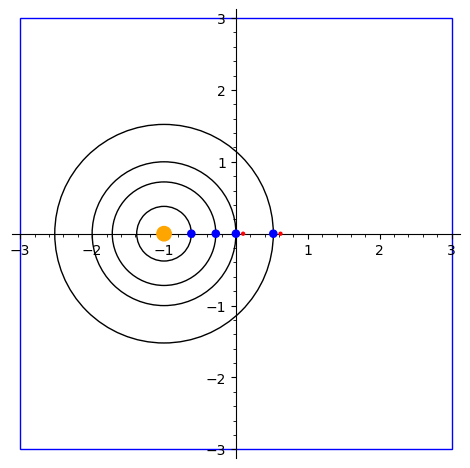

In [4]:
def dessine_planetes(k):
    plt = polygon2d([(-3,-3),(-3,3),(3,3),(3,-3)], fill = False) 
    angl = {}
    for i in theta_jour.keys():
        angl[i] = 5*k* theta_jour[i]
    xSoleil = -distances_soleil["Terre"] * cos(angl["Terre"])
    ySoleil = -distances_soleil["Terre"] * sin(angl["Terre"])
    plt += circle((xSoleil,ySoleil), 0.1, fill = True, color = "orange")

    for i in distances_soleil.keys():
        plt += circle((xSoleil,ySoleil), distances_soleil[i] , fill = False, color = "black")
        plt += circle((xSoleil + distances_soleil[i]*cos(angl[i]),ySoleil + distances_soleil[i]*sin(angl[i])), 0.05 , fill = True, color = "blue")
    
    plt += circle((Lune[1]*cos(5*k*Lune[3]),Lune[1]*sin(5*k*Lune[3])), 0.02 , fill = True, color = "red")
    plt += circle((xSoleil+distances_soleil["Mars"]*cos(angl["Mars"])+Deimos[1]*cos(5*k*Deimos[3]),ySoleil+distances_soleil["Mars"]*sin(angl["Mars"])+Deimos[1]*sin(5*k*Deimos[3])), 0.02 , fill = True, color = "red")

    return plt


liste = [dessine_planetes(k) for k in range(73)]


a = animate(liste)
a.show()

In [5]:
def dessine_planetes_traj(k):
    plt = polygon2d([(-3,-3),(-3,3),(3,3),(3,-3)], fill = False) 
    plt2 = polygon2d([(-3,-3),(-3,3),(3,3),(3,-3)], fill = False) 
    plt3 = polygon2d([(-3,-3),(-3,3),(3,3),(3,-3)], fill = False) 
    plt4 = polygon2d([(-3,-3),(-3,3),(3,3),(3,-3)], fill = False) 
    plt += circle((0,0), 0.05, fill = True, color = "blue")
    plt2 += circle((0,0), 0.05, fill = True, color = "blue")
    plt3 += circle((0,0), 0.05, fill = True, color = "blue")
    plt4 += circle((0,0), 0.05, fill = True, color = "blue")

    for j in range(k):
        angl = {}
        for i in theta_jour.keys():
            angl[i] = 2*j* theta_jour[i]
        xSoleil = -distances_soleil["Terre"] * cos(angl["Terre"])
        ySoleil = -distances_soleil["Terre"] * sin(angl["Terre"])
        plt += point2d((xSoleil,ySoleil), color = "orange")
        plt2 += point2d((xSoleil + distances_soleil["Mercure"]*cos(angl["Mercure"]),ySoleil + distances_soleil["Mercure"]*sin(angl["Mercure"])), color = "blue")
        plt3 += point2d((xSoleil + distances_soleil["Vénus"]*cos(angl["Vénus"]),ySoleil + distances_soleil["Vénus"]*sin(angl["Vénus"])), color = "blue")
        plt4 += point2d((xSoleil + distances_soleil["Mars"]*cos(angl["Mars"]),ySoleil + distances_soleil["Mars"]*sin(angl["Mars"])), color = "blue")
        plt4 += point2d((xSoleil+distances_soleil["Mars"]*cos(angl["Mars"])+Deimos[1]*cos(2*j*Deimos[3]),ySoleil+distances_soleil["Mars"]*sin(angl["Mars"])+Deimos[1]*sin(2*k*Deimos[3])), color = "red")
        plt += point2d((Lune[1]*cos(2*j*Lune[3]),Lune[1]*sin(2*j*Lune[3])), color = "red")
    plt5 = plt + plt2 + plt3 + plt4
    return plt,plt2,plt3,plt4,plt5

plt,plt2,plt3,plt4,plt5 = dessine_planetes_traj(400)


Trajectoire du Soleil et de la Lune dans le référentiel géocentrique

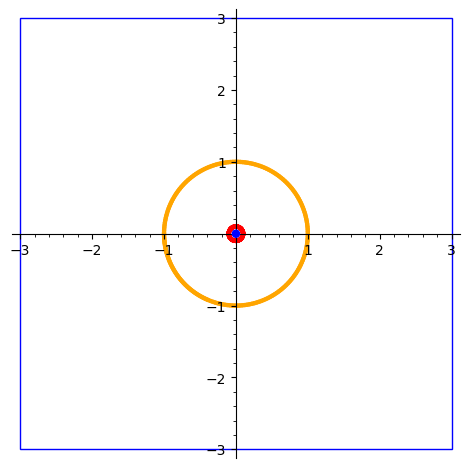

In [6]:
plt

Trajectoire de Mercure dans le référentiel géocentrique

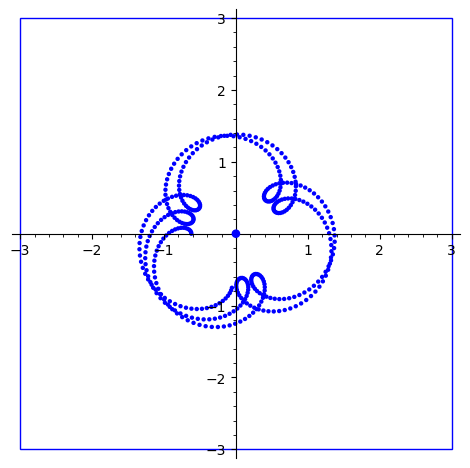

In [7]:
plt2

Trajectoire de Vénus dans le référentiel géocentrique

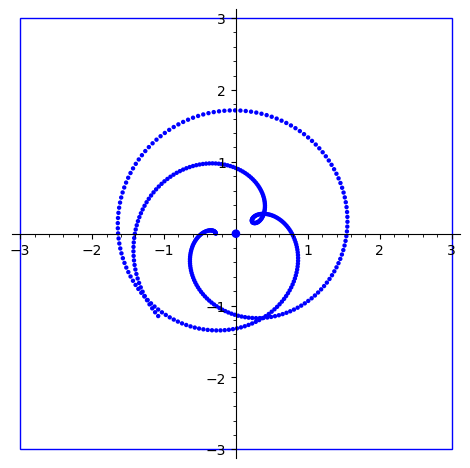

In [8]:
plt3

Trajectoire de Mars et Déimos dans le référentiel géocentrique

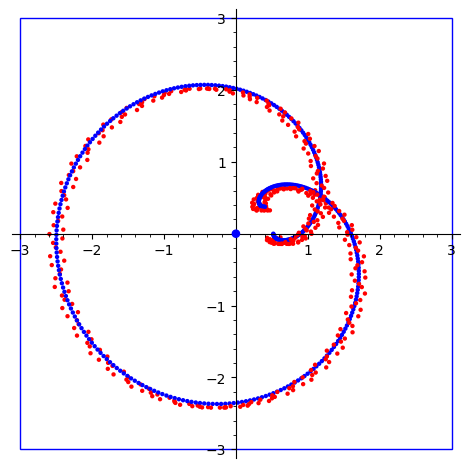

In [9]:
plt4

Les 4 premiers Schémas superposés

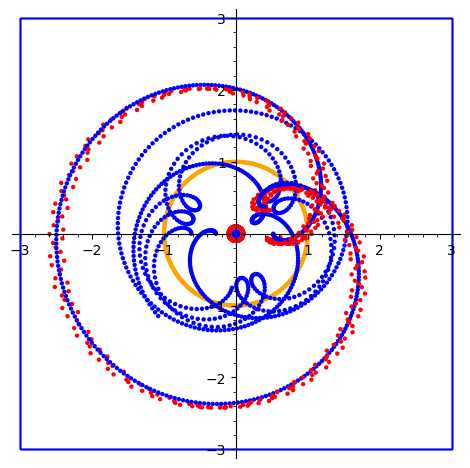

In [10]:
plt5

# Modélisation 2D - Ellipses

In [11]:
ua = 149597887.5
Planetes = {
    "Mercure": {"T_revol_j" :87.969, "Demi_g_axe_km" : 57909050, "Périhélie_km" : 46001200}, 
    "Vénus": {"T_revol_j" :224.701, "Demi_g_axe_km" : 108209500, "Périhélie_km" : 107476000},
    "Terre": {"T_revol_j" :365.257, "Demi_g_axe_km" : 149597887.5, "Périhélie_km" : 147098074}, 
    "Mars": {"T_revol_j" :686.96,"Demi_g_axe_km" : 227944000, "Périhélie_km" : 206655000}, 
}
for i in Planetes.keys():
    Planetes[i]["C"] =  Planetes[i]["Demi_g_axe_km"] - Planetes[i]["Périhélie_km"]
    Planetes[i]["Demi_g_axe_ua"] =  Planetes[i]["Demi_g_axe_km"]/ua
    Planetes[i]["C_ua"] =  Planetes[i]["C"]/ua
    Planetes[i]["Demi_p_axe_ua"] =  sqrt(Planetes[i]["Demi_g_axe_ua"]**2 - Planetes[i]["C_ua"]**2)

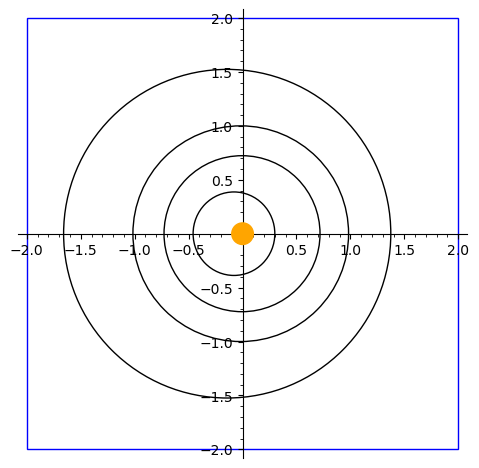

In [12]:
def dessine_planetes_ellipse():
    plt = polygon2d([(-2,-2),(-2,2),(2,2),(2,-2)], fill = False) 
    plt += circle((0,0), 0.1, fill = True, color = "orange")
    for i in distances_soleil.keys():
        plt += ellipse((-Planetes[i]["C_ua"],0), Planetes[i]["Demi_g_axe_ua"],Planetes[i]["Demi_p_axe_ua"] , pi/2,fill = False, color = "black")

    return plt
a = dessine_planetes_ellipse()

a.show()